In [1]:
# ==============================================================
# INSTALL REQUIRED LIBRARIES
# ==============================================================

!pip install pandas scikit-learn seaborn matplotlib imbalanced-learn


In [2]:
# ==============================================================
#  IMPORT LIBRARIES
# ==============================================================

import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

# Configuration
sns.set(style="whitegrid", palette="muted", font_scale=1.1)
np.random.seed(42)


In [4]:
# ==============================================================
# LOAD DATASET
# ==============================================================

df = pd.read_csv("/content/AsjadComments.csv")

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (10634, 2)


,text,label
0,Ya jo log idher galiyan de rha ha unko chahia ...,non-abusive
1,What do you guys think now after he apologized ?,non-abusive
2,Junaid Bhai woh Islamabad Airport auction hoga...,non-abusive
3,So disappointed with your video,non-abusive
4,Lol. I&#39;m from interior sindh and even my c...,abusive


Column Names: ['text', 'label']

Label Distribution:
label
non-abusive    9688
abusive         946
Name: count, dtype: int64


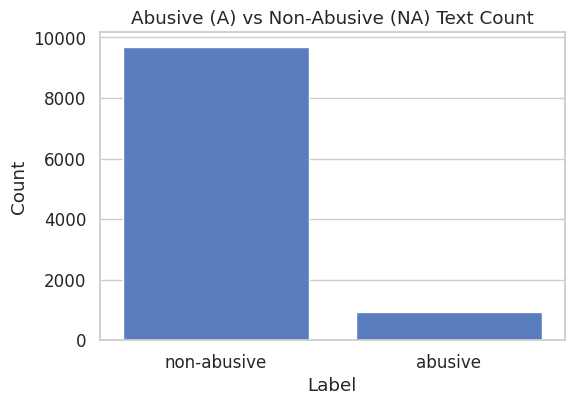

In [5]:
# ==============================================================
# DATASET OVERVIEW
# ==============================================================

print("Column Names:", df.columns.tolist())
print("\nLabel Distribution:")
print(df['label'].value_counts())

# Visualize Label Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df)
plt.title("Abusive (A) vs Non-Abusive (NA) Text Count")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


Missing Values per Column:
 text     0
label    0
dtype: int64

Duplicate Rows Found: 255


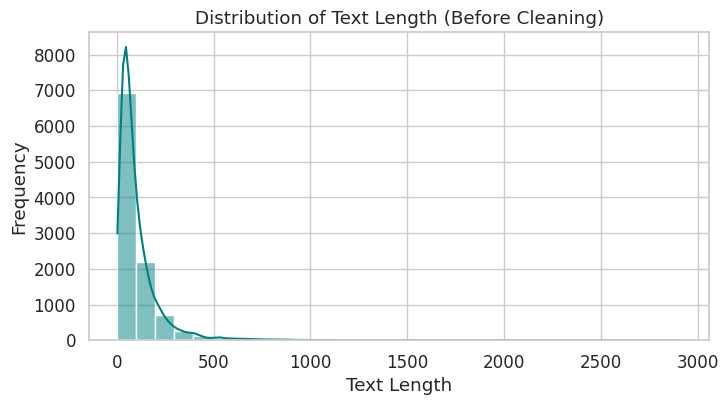

Dataset Shape after Cleaning: (10275, 3)


In [6]:
# ==============================================================
# DATA CLEANING: MISSING VALUES, DUPLICATES, OUTLIERS
# ==============================================================

# Missing Values
print("Missing Values per Column:\n", df.isnull().sum())

# Drop rows with missing text
df = df.dropna(subset=['text'])

# Duplicates
print("\nDuplicate Rows Found:", df.duplicated().sum())
df = df.drop_duplicates()

# Add text length column
df['text_length'] = df['text'].apply(len)

# Plot distribution of text length
plt.figure(figsize=(8,4))
sns.histplot(df['text_length'], bins=30, kde=True, color='teal')
plt.title("Distribution of Text Length (Before Cleaning)")
plt.xlabel("Text Length")
plt.ylabel("Frequency")
plt.show()

# Remove extreme outliers (top 1%)
threshold = df['text_length'].quantile(0.99)
df = df[df['text_length'] < threshold]

print("Dataset Shape after Cleaning:", df.shape)


In [7]:
df.head()

,text,label,text_length
0,Ya jo log idher galiyan de rha ha unko chahia ...,non-abusive,170
1,What do you guys think now after he apologized ?,non-abusive,48
2,Junaid Bhai woh Islamabad Airport auction hoga...,non-abusive,78
3,So disappointed with your video,non-abusive,31
4,Lol. I&#39;m from interior sindh and even my c...,abusive,117


In [9]:
# ==============================================================
# TEXT PREPROCESSING: CLEANING AND NORMALIZATION
# ==============================================================

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", '', text)      # remove URLs
    text = re.sub(r'\d+', '', text)                 # remove numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)         # remove special characters
    text = re.sub(r'\s+', ' ', text).strip()        # normalize whitespace
    return text

df['clean_text'] = df['text'].apply(clean_text)

# Extended Roman Urdu stopword list (expandable)
roman_urdu_stopwords = [
    'ka','ki','ke','mein','tu','tum','tera','teri','wo','woh','se','aur','ko','tha','thi','the',
    'kaun','kya','kab','kyun','ye','han','nai','nahi','acha','bura','lekin','ab','jab','toh','kar',
    'kr','bhi','raha','rahi','rahe','gaya','gayi','hain','hai','ho','hon','sirf','bas','kuch','par',
    'magar','phir','us','inka','unka','mera','meri','hum','apna','tumhara','unka','inka','woh','unko'
]

df['clean_text'] = df['clean_text'].apply(
    lambda x: ' '.join([word for word in x.split() if word not in roman_urdu_stopwords])
)

print("Sample of Cleaned Text:\n")
df.head(20)


Sample of Cleaned Text:



,text,label,text_length,clean_text
0,Ya jo log idher galiyan de rha ha unko chahia ...,non-abusive,170,ya jo log idher galiyan de rha ha chahia khud ...
1,What do you guys think now after he apologized ?,non-abusive,48,what do you guys think now after he apologized
2,Junaid Bhai woh Islamabad Airport auction hoga...,non-abusive,78,junaid bhai islamabad airport auction hogaya i...
3,So disappointed with your video,non-abusive,31,so disappointed with your video
4,Lol. I&#39;m from interior sindh and even my c...,abusive,117,lol im from interior sindh and even my city is...
5,U are literally an inspirational person for ne...,non-abusive,126,u are literally an inspirational person for ne...
6,AFTER 2 MONTHS CAME BACK ON THIS VIDEO JUST T...,non-abusive,84,after months came back on this video just to s...
7,Lakh lanat yar. 2 number govt ko support krny par,non-abusive,49,lakh lanat yar number govt support krny
8,This is your voice which we know You as a Juni...,non-abusive,55,this is your voice which we know you as a juni...
9,Successful economies got there by setting exam...,non-abusive,148,successful economies got there by setting exam...


Feature Matrix Shape: (10275, 5000)


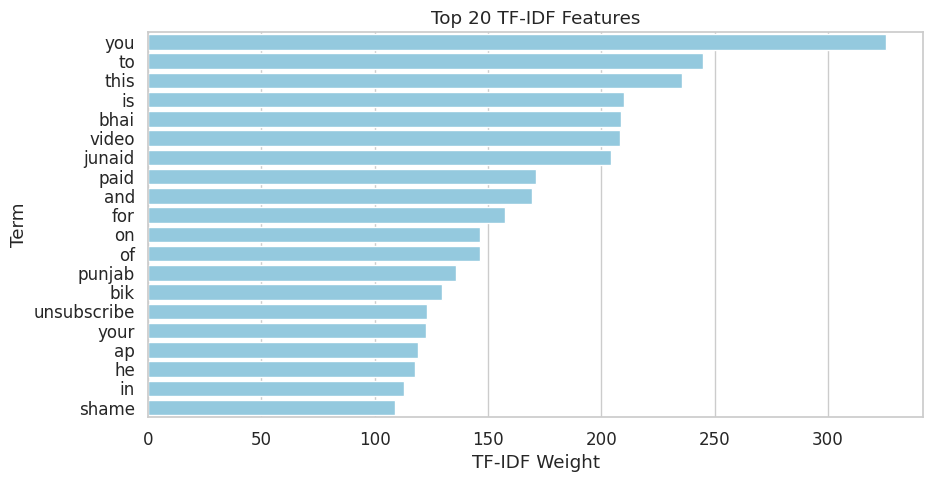

In [10]:
# ==============================================================
# FEATURE EXTRACTION USING TF-IDF
# ==============================================================

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = vectorizer.fit_transform(df['clean_text'])
y = df['label']

print("Feature Matrix Shape:", X.shape)

# Plot top TF-IDF features (optional visualization)
feature_names = vectorizer.get_feature_names_out()
sums = X.sum(axis=0).A1
data = pd.DataFrame({'term': feature_names, 'tfidf': sums}).sort_values('tfidf', ascending=False).head(20)

plt.figure(figsize=(10,5))
sns.barplot(x='tfidf', y='term', data=data, color='skyblue')
plt.title("Top 20 TF-IDF Features")
plt.xlabel("TF-IDF Weight")
plt.ylabel("Term")
plt.show()


Before SMOTE: {'non-abusive': 9394, 'abusive': 881}
After SMOTE: {'non-abusive': 9394, 'abusive': 9394}


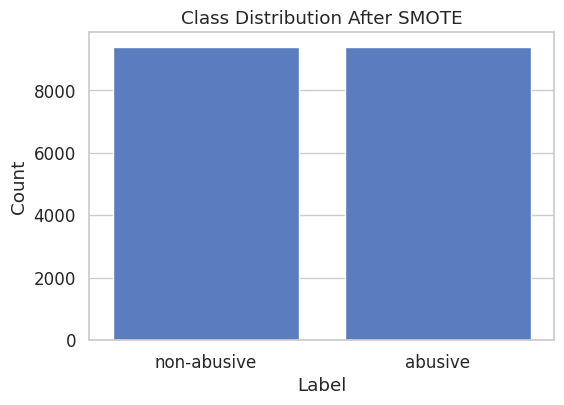

In [11]:
# ==============================================================
# HANDLE CLASS IMBALANCE USING SMOTE
# ==============================================================

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Before SMOTE:", y.value_counts().to_dict())
print("After SMOTE:", y_resampled.value_counts().to_dict())

# Plot class balance after resampling
plt.figure(figsize=(6,4))
sns.countplot(x=y_resampled)
plt.title("Class Distribution After SMOTE")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


In [12]:
# ==============================================================
# TRAIN-TEST SPLIT (75% TRAIN / 25% TEST)
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.25, random_state=42, stratify=y_resampled
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (14091, 5000)
Testing Data Shape: (4697, 5000)


In [13]:
# ==============================================================
# TRAIN MULTIPLE MODELS AND EVALUATE PERFORMANCE
# ==============================================================

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "SVM (Linear)": LinearSVC()
}

results = {}

for name, model in models.items():
    print("\n==============================")
    print(f"Training {name}")
    print("==============================")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))



Training Logistic Regression
Accuracy: 0.9099
              precision    recall  f1-score   support

     abusive       0.89      0.94      0.91      2349
 non-abusive       0.93      0.88      0.91      2348

    accuracy                           0.91      4697
   macro avg       0.91      0.91      0.91      4697
weighted avg       0.91      0.91      0.91      4697


Training Decision Tree
Accuracy: 0.9512
              precision    recall  f1-score   support

     abusive       0.94      0.96      0.95      2349
 non-abusive       0.96      0.94      0.95      2348

    accuracy                           0.95      4697
   macro avg       0.95      0.95      0.95      4697
weighted avg       0.95      0.95      0.95      4697


Training Random Forest
Accuracy: 0.9832
              precision    recall  f1-score   support

     abusive       0.99      0.98      0.98      2349
 non-abusive       0.98      0.99      0.98      2348

    accuracy                           0.98      4697

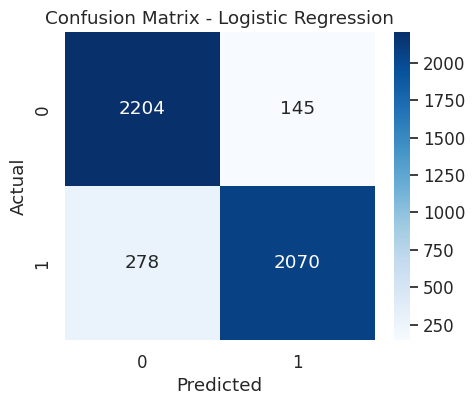

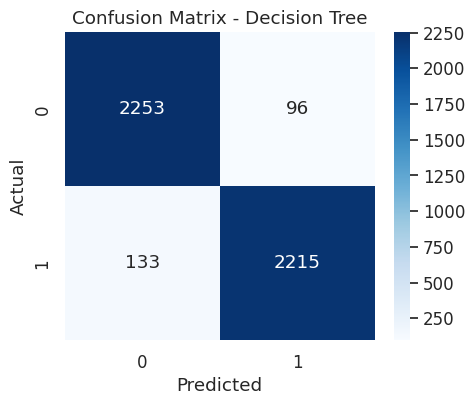

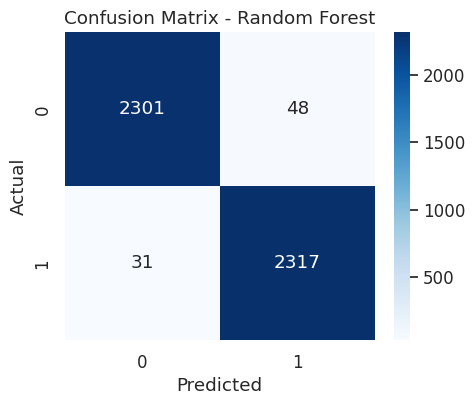

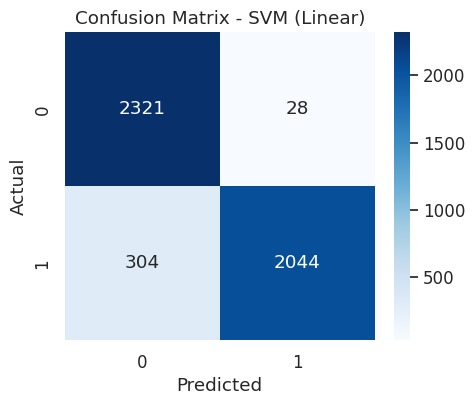

In [17]:
# ==============================================================
# CONFUSION MATRIX FOR EACH MODEL
# ==============================================================

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.909943,0.911260,0.909943,0.909870
1,Decision Tree,0.951245,0.951357,0.951245,0.951242
2,Random Forest,0.983181,0.983206,0.983181,0.983181
3,SVM (Linear),0.929317,0.935328,0.929317,0.929071


<Figure size 800x500 with 0 Axes>

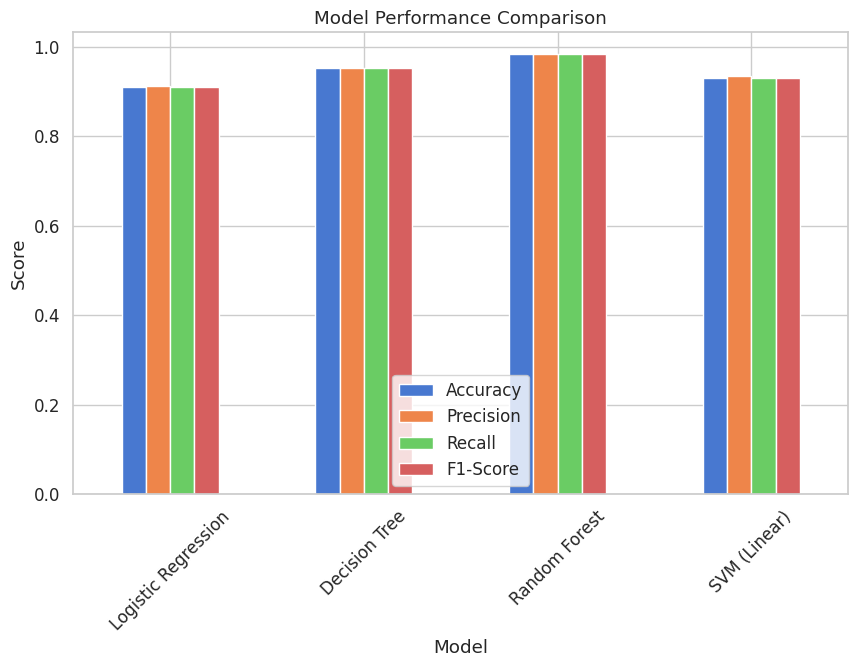

In [18]:
# ==============================================================
#  MODEL PERFORMANCE COMPARISON
# ==============================================================

metrics = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    report = classification_report(y_test, y_pred, output_dict=True)
    metrics.append({
        'Model': name,
        'Accuracy': report['accuracy'],
        'Precision': report['weighted avg']['precision'],
        'Recall': report['weighted avg']['recall'],
        'F1-Score': report['weighted avg']['f1-score']
    })

results_df = pd.DataFrame(metrics)
display(results_df)

# Bar plot comparison
plt.figure(figsize=(8,5))
results_df.plot(x='Model', y=['Accuracy', 'Precision', 'Recall', 'F1-Score'], kind='bar', figsize=(10,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


In [19]:
# ==============================================================
#  FINAL VERDICT AND BEST MODEL
# ==============================================================

print("FINAL PERFORMANCE SUMMARY:\n")
print(results_df.sort_values(by='Accuracy', ascending=False))

best_model = results_df.sort_values(by='Accuracy', ascending=False).iloc[0]
print(f"\nBest Performing Model: {best_model['Model']} with Accuracy = {best_model['Accuracy']:.4f}")


FINAL PERFORMANCE SUMMARY:

                 Model  Accuracy  Precision    Recall  F1-Score
2        Random Forest  0.983181   0.983206  0.983181  0.983181
1        Decision Tree  0.951245   0.951357  0.951245  0.951242
3         SVM (Linear)  0.929317   0.935328  0.929317  0.929071
0  Logistic Regression  0.909943   0.911260  0.909943  0.909870

Best Performing Model: Random Forest with Accuracy = 0.9832


In [23]:
# ============================================
# Save Trained Models and TF-IDF Vectorizer
# ============================================

import joblib

# Save each trained model
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + "_model.joblib"
    joblib.dump(model, filename)
    print(f"Model saved successfully: {filename}")

# Save the TF-IDF vectorizer
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")
print("TF-IDF vectorizer saved successfully: tfidf_vectorizer.joblib")

print("\nAll trained components have been saved successfully and are ready for deployment.")


Model saved successfully: logistic_regression_model.joblib
Model saved successfully: decision_tree_model.joblib
Model saved successfully: random_forest_model.joblib
Model saved successfully: svm_(linear)_model.joblib
TF-IDF vectorizer saved successfully: tfidf_vectorizer.joblib

All trained components have been saved successfully and are ready for deployment.
